## 1. Imports and setup ##

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from opa import array_intensity, find_peaks

wl = 1.55e-6          # wavelength: 1550 nm
N = 16                # number of emitters
theta = np.radians(np.linspace(-90, 90, 3601))

## 2. Steering ##

unsteered: peak at 0.00°
steered to 30°: peak at 30.00°


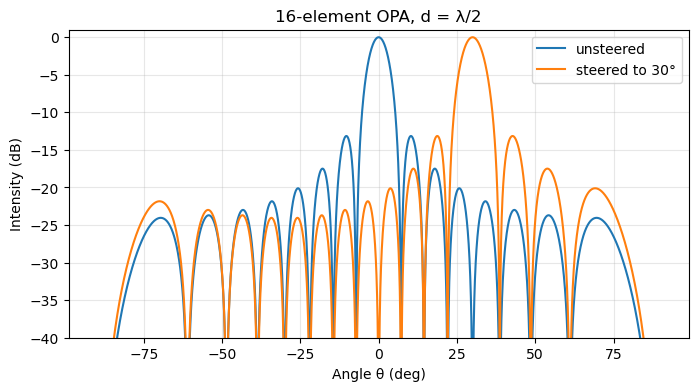

In [4]:
d = wl / 2
target = np.radians(30)
dphi = 2 * np.pi * d / wl * np.sin(target)

plt.figure(figsize=(8, 4))
for dp, label in [(0, "unsteered"), (dphi, "steered to 30°")]:
    I = array_intensity(theta, N, d, wl, dp)
    plt.plot(np.degrees(theta), 10 * np.log10(I + 1e-12), label=label)
    print(f"{label}: peak at {np.degrees(theta[I.argmax()]):.2f}°")

plt.ylim(-40, 1)
plt.xlabel("Angle θ (deg)"); plt.ylabel("Intensity (dB)")
plt.title(f"{N}-element OPA, d = λ/2")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [5]:
## 3. Sidelobe check ##

In [6]:
I = array_intensity(theta, N, wl / 2, wl, 0)
angles, vals = find_peaks(theta, I)
print(f"Strongest sidelobe: {10*np.log10(np.sort(vals)[-2]):.1f} dB")

Strongest sidelobe: -13.1 dB


In [7]:
## 4. Your first grating lobe ## 

Strong beams at: [-30.  30.] deg


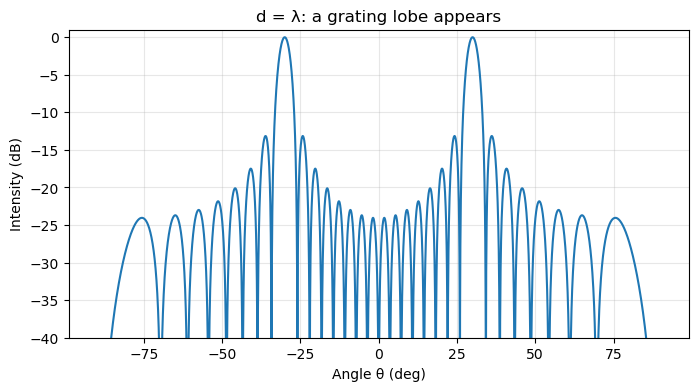

In [8]:
d = wl                                # spacing = one wavelength
dphi = 2 * np.pi * d / wl * np.sin(np.radians(30))
I = array_intensity(theta, N, d, wl, dphi)

angles, vals = find_peaks(theta, I, threshold=0.5)
print("Strong beams at:", np.round(angles, 1), "deg")

plt.figure(figsize=(8, 4))
plt.plot(np.degrees(theta), 10 * np.log10(I + 1e-12))
plt.ylim(-40, 1)
plt.xlabel("Angle θ (deg)"); plt.ylabel("Intensity (dB)")
plt.title("d = λ: a grating lobe appears")
plt.grid(alpha=0.3); plt.show()